In [1]:
import matplotlib.pyplot as plt
import torch
%matplotlib inline

In [ ]:
words = open('names.txt', 'r').read().splitlines()
char = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(char)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}

In [5]:
def build_dataset(words, block_size=4):
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix] #crop and append
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(f"X.shape: {X.shape}, Y.shape: {Y.shape}")
    return X, Y
import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xv, Yv = build_dataset(words[n1:n2]) # 10% after training set
Xt, Yt = build_dataset(words[n2:]) # 10% after validation set

X.shape: torch.Size([182625, 4]), Y.shape: torch.Size([182625])
X.shape: torch.Size([22655, 4]), Y.shape: torch.Size([22655])
X.shape: torch.Size([22866, 4]), Y.shape: torch.Size([22866])


In [7]:
block_size = 4
embedding_size = 10
hidden_size = 400
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((len(stoi), embedding_size), generator=g)
W1 = torch.randn((block_size * embedding_size, hidden_size), generator=g) * 0.1
b1 = torch.zeros(hidden_size)
W2 = torch.randn((hidden_size, len(stoi)), generator=g) * 0.1
b2 = torch.zeros(len(stoi))
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad_()

In [9]:
lri = []
lossi = []
stepi = []

In [10]:
for i in range(50000):
    # mini batch
    ix = torch.randint(0, Xtr.shape[0], (64,))
    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(emb.shape[0], -1) @ W1 + b1)
    logits = h @ W2 + b2
    reg_loss = 1e-4 * (W1.pow(2).mean() + W2.pow(2).mean())
    loss = torch.nn.functional.cross_entropy(logits, Ytr[ix]) + reg_loss

    # backward pass
    for p in [C, W1, b1, W2, b2]:
        p.grad = None
    loss.backward()
    # update parameters
    lr = 0.05 if i < 30000 else 0.01
    for p in [C, W1, b1, W2, b2]:
        p.data += -lr * p.grad

    stepi.append(i)
    lossi.append(loss.item())

print(loss.item())

1.829289197921753


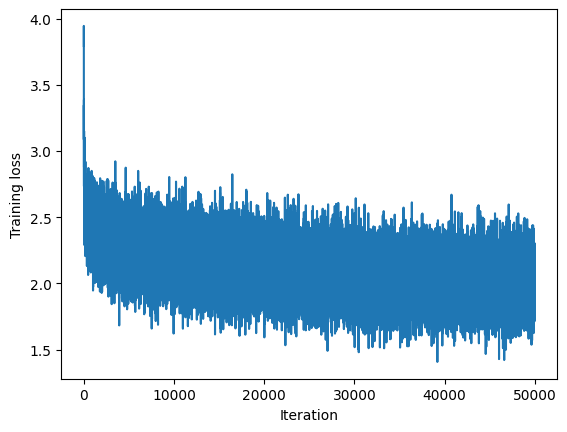

In [11]:
plt.plot(stepi, lossi)
plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.show()

In [13]:
# checking on cross- validation set
emb = C[Xv]
h = torch.tanh(emb.view(emb.shape[0], -1) @ W1 + b1)
logits = h @ W2 + b2
loss = torch.nn.functional.cross_entropy(logits, Yv)
loss

tensor(2.0630, grad_fn=<NllLossBackward0>)

In [14]:
import torch.nn.functional as F

def evaluate(X, Y):
    with torch.no_grad():
        emb = C[X]
        h = torch.tanh(emb.view(emb.shape[0], -1) @ W1 + b1)
        logits = h @ W2 + b2
        return F.cross_entropy(logits, Y).item()
print("training loss:", evaluate(Xtr, Ytr))
print("validation loss:", evaluate(Xv, Yv))
print("test loss:", evaluate(Xt, Yt))

training loss: 2.0031535625457764
validation loss: 2.062958002090454
test loss: 2.062753915786743


In [15]:
import torch.nn.functional as F

with torch.no_grad():
    for _ in range(20):
        out = []
        context = [0] * block_size

        for _ in range(30):  # maximum generated name length
            x = torch.tensor([context])
            emb = C[x]

            h = torch.tanh(
                emb.view(emb.shape[0], -1) @ W1 + b1
            )
            logits = h @ W2 + b2

            probs = F.softmax(logits, dim=1)
            ix = torch.multinomial(probs, num_samples=1).item()

            context = context[1:] + [ix]

            if ix == 0:
                break

            out.append(ix)

        print("".join(itos[i] for i in out))

grayann
jana
jay
karlyn
baseel
alyssabello
finna
viley
jolishah
jobist
melden
phpell
anely
harbee
ahman
coroni
shameelee
rolete
caanire
elivie
